<a href="https://colab.research.google.com/github/atebha/MIS-769-Big-Data/blob/repocleanup/HW08_prompt_engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HW8 Lab: Prompt Engineering ✍️🤖

<!-- lab-header:begin -->
**MIS 769 · Big Data Analytics for Business · Fall 2026**

**Points:** 40  |  **Due:** Sunday, November 1, 2026 at 10:00 PM Pacific

**Dr. Richard J. Young** · UNLV Lee Business School
<!-- lab-header:end -->

> **Why are we learning this?** The cheapest, fastest way to improve an LLM system is
> almost never a bigger model — it's a better prompt. Zero-shot, few-shot,
> chain-of-thought, role, structured output: these five patterns work on every model
> from a 250M-parameter local one to a frontier API, and they will outlive whichever
> model is fashionable this year. The transferable skill: **programming a model
> through its context — and iterating on prompts like an engineer, with versions and
> evidence, not vibes.**

**How this lab works:** every cell below runs as-is — Runtime → Run all walks the
whole prompting ladder on a scored test set. Your job: (1) understand why each rung
beats the one below it, (2) break things on purpose in the 🧪 Experiment cells, and
(3) rebuild the prompt library for **a domain you're passionate about** in the 🎮
Playground — that run is where your grade lives.

**Honest note about our model:** we use a *small local* model on purpose. Frontier
models are so capable they often succeed despite a bad prompt — you can't see your
prompt working. Small models fail visibly, so the difference between a weak prompt and
a strong one is **dramatic and measurable**. Learn on the small model; the optional
cell at the end shows the same prompts on a frontier model for contrast.


## Learning objectives

- Write zero-shot prompts and measure where they fail
- Improve accuracy with few-shot examples and explain why it works
- Use chain-of-thought for multi-step reasoning tasks
- Iterate one business prompt v1→v4, documenting what changed and what improved


## Part 1: Setup and Zero-Shot Prompts (6 pts)

Model choice: **`google/flan-t5-base`** (~250M parameters, instruction-tuned). Why
base and not large? base loads in seconds, runs prompt-by-prompt on the free Colab CPU
with no memory pressure, and is *just* capable enough that good prompting visibly
rescues it. (flan-t5-large also fits free Colab if you have a T4 — feel free to try
it and compare.) Why not gpt2? gpt2 was never instruction-tuned: it doesn't follow
instructions at all, it only continues text.


In [ ]:
!pip install -q transformers accelerate

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# flan-t5 is a seq2seq (encoder-decoder) model. transformers v5 removed the
# "text2text-generation" pipeline task, and routing T5 through "text-generation"
# runs but returns garbage, so we call the seq2seq classes directly.
_tok = AutoTokenizer.from_pretrained("google/flan-t5-base")
_mod = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-base")

def generate(prompt, max_tokens=100, **params):
    """Helper: run one prompt, return the model's text."""
    ids = _tok(prompt, return_tensors="pt", truncation=True, max_length=512)
    out = _mod.generate(**ids, max_new_tokens=max_tokens, **params)
    return _tok.decode(out[0], skip_special_tokens=True)

print("✅ Model loaded. Smoke test:", generate("Translate to French: Good morning"))

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

✅ Model loaded. Smoke test: Bonjour, m'ai bien l'heure.


[link text](https://)**Zero-shot** = just ask. No examples, no reasoning scaffold. This is your
baseline — every technique that follows must beat it to earn its keep.


In [ ]:
# Zero-shot classification and summarization — the baseline.
zero_shot_prompt = """Classify the following customer review as POSITIVE, NEGATIVE, or NEUTRAL.

Review: "The product arrived quickly but the quality was disappointing."
Classification:"""
print("Zero-shot classification:", generate(zero_shot_prompt, max_tokens=10))

summary_prompt = """Summarize in one sentence: Our Q3 revenue grew 12 percent to 4.2
million dollars, driven mostly by the new enterprise tier, but customer churn in the
consumer segment rose from 3 to 5 percent, which the team attributes to the price
increase in July."""
print("\nZero-shot summary:", generate(summary_prompt, max_tokens=60))

Zero-shot classification: NEGATIVE

Zero-shot summary: Revenue in Q3 grew 12 percent to 4.2 million dollars, driven mostly by the new enterprise tier, but customer churn in the consumer segment rose from 3 to 5 percent.


In [ ]:
# Build a small labeled test set so "better" is a NUMBER, not an opinion.
test_reviews = [
    ("Absolutely love it, best purchase I made all year!", "POSITIVE"),
    ("Broke after two days and support never answered my emails.", "NEGATIVE"),
    ("It does what it says. Nothing more, nothing less.", "NEUTRAL"),
    ("Not bad for the price, though I probably would not buy it again.", "NEUTRAL"),
    ("The delivery was fast but the product is a complete waste of money.", "NEGATIVE"),
    ("Exceeded my expectations, my whole team uses it daily now.", "POSITIVE"),
]

def score_prompt(prompt_fn, name):
    """Run a prompt-builder over the test set and report accuracy."""
    correct = 0
    for review, label in test_reviews:
        answer = generate(prompt_fn(review), max_tokens=8).strip().upper()
        hit = label in answer
        correct += hit
        print(f"  {'✓' if hit else '✗'} expected {label:8s} got: {answer[:30]}")
    print(f"{name}: {correct}/{len(test_reviews)} correct\n")
    return correct

def zero_shot(review):
    return f"""Classify the following customer review as POSITIVE, NEGATIVE, or NEUTRAL.

Review: "{review}"
Classification:"""

zs_score = score_prompt(zero_shot, "ZERO-SHOT")

  ✓ expected POSITIVE got: POSITIVE
  ✓ expected NEGATIVE got: NEGATIVE
  ✗ expected NEUTRAL  got: POSITIVE
  ✗ expected NEUTRAL  got: NEGATIVE
  ✓ expected NEGATIVE got: NEGATIVE
  ✓ expected POSITIVE got: POSITIVE
ZERO-SHOT: 4/6 correct



### 🧪 Experiment

- Reword the instruction — drop NEUTRAL from the option list — and re-score. Where do the NEUTRAL reviews land when the model isn't offered the category?
- Change the label set to `GOOD / BAD / OKAY` in both the prompt and (mentally) the test labels. Does the model handle informal labels as well as the shouty ones?
- Delete the final `Classification:` line and re-run one review. How much of zero-shot's reliability was that one formatting cue?


In [ ]:
# Part 1 experiment 1

def zero_shot_no_neutral(review):
    return f"""Classify the following customer review as POSITIVE or NEGATIVE.

Review: "{review}"
Classification:"""

# 1) Re-score the whole test set. The two NEUTRAL reviews can't count as hits now,
#    so the best possible score is 4/6.
no_neutral_score = score_prompt(zero_shot_no_neutral, "ZERO-SHOT (no NEUTRAL)")

# 2) Where do the NEUTRAL reviews land? Compare against the original prompt.
print("NEUTRAL reviews: original prompt vs. NEUTRAL removed")
for review, label in test_reviews:
    if label == "NEUTRAL":
        before = generate(zero_shot(review), max_tokens=8).strip().upper()
        after = generate(zero_shot_no_neutral(review), max_tokens=8).strip().upper()
        print(f"  {before:10s} -> {after:10s} | {review}")

print(f"\nBaseline: {zs_score}/6   No-NEUTRAL: {no_neutral_score}/6")

  ✓ expected POSITIVE got: POSITIVE
  ✓ expected NEGATIVE got: NEGATIVE
  ✗ expected NEUTRAL  got: POSITIVE
  ✗ expected NEUTRAL  got: NEGATIVE
  ✓ expected NEGATIVE got: NEGATIVE
  ✓ expected POSITIVE got: POSITIVE
ZERO-SHOT (no NEUTRAL): 4/6 correct

NEUTRAL reviews: original prompt vs. NEUTRAL removed
  POSITIVE   -> POSITIVE   | It does what it says. Nothing more, nothing less.
  NEGATIVE   -> NEGATIVE   | Not bad for the price, though I probably would not buy it again.

Baseline: 4/6   No-NEUTRAL: 4/6


In [ ]:
# Part 1 experiment 2
label_map = {"POSITIVE": "GOOD", "NEGATIVE": "BAD", "NEUTRAL": "OKAY"}
informal_reviews = [(review, label_map[label]) for review, label in test_reviews]

def zero_shot_informal(review):
    return f"""Classify the following customer review as GOOD, BAD, or OKAY.

Review: "{review}"
Classification:"""

def score_informal(prompt_fn, name):
    """Same idea as score_prompt, but against the GOOD/BAD/OKAY labels."""
    correct = 0
    for review, label in informal_reviews:
        answer = generate(prompt_fn(review), max_tokens=8).strip().upper()
        hit = label in answer
        correct += hit
        print(f"  {'✓' if hit else '✗'} expected {label:5s} got: {answer[:30]}")
    print(f"{name}: {correct}/{len(informal_reviews)} correct\n")
    return correct

informal_score = score_informal(zero_shot_informal, "ZERO-SHOT (GOOD/BAD/OKAY)")
print(f"Baseline (POSITIVE/NEGATIVE/NEUTRAL): {zs_score}/6   Informal: {informal_score}/6")

  ✓ expected GOOD  got: GOOD
  ✓ expected BAD   got: BAD
  ✓ expected OKAY  got: OKAY
  ✗ expected OKAY  got: BAD
  ✓ expected BAD   got: BAD
  ✓ expected GOOD  got: GOOD
ZERO-SHOT (GOOD/BAD/OKAY): 5/6 correct

Baseline (POSITIVE/NEGATIVE/NEUTRAL): 4/6   Informal: 5/6


In [ ]:
# Part 1 experiment 3

def zero_shot_no_cue(review):
    return f"""Classify the following customer review as POSITIVE, NEGATIVE, or NEUTRAL.

Review: "{review}\""""

# 1) One review, side by side.
sample = test_reviews[1][0]   # "Broke after two days and support never answered my emails."
print("Review:", sample)
print("  With cue   :", repr(generate(zero_shot(sample), max_tokens=8)))
print("  Without cue:", repr(generate(zero_shot_no_cue(sample), max_tokens=8)))

# 2) Full re-score, so the effect is a number instead of an impression.
no_cue_score = score_prompt(zero_shot_no_cue, "ZERO-SHOT (no 'Classification:' cue)")
print(f"Baseline: {zs_score}/6   No cue: {no_cue_score}/6")

Review: Broke after two days and support never answered my emails.
  With cue   : 'NEGATIVE'
  Without cue: 'NEGATIVE'
  ✓ expected POSITIVE got: POSITIVE
  ✓ expected NEGATIVE got: NEGATIVE
  ✗ expected NEUTRAL  got: POSITIVE
  ✗ expected NEUTRAL  got: POSITIVE
  ✓ expected NEGATIVE got: NEGATIVE
  ✓ expected POSITIVE got: POSITIVE
ZERO-SHOT (no 'Classification:' cue): 4/6 correct

Baseline: 4/6   No cue: 4/6


## Part 2: Few-Shot Prompts (10 pts)

**Few-shot** = show the model 2–5 worked examples before your real input. You're not
teaching it new knowledge — you're showing it the *format and decision boundary* you
want (what counts as NEUTRAL is exactly what zero-shot gets wrong most). Note the
examples below are NOT from the test set — reusing test items would be cheating,
in class and in production.


In [ ]:
def few_shot(review):
    return f"""Classify customer reviews as POSITIVE, NEGATIVE, or NEUTRAL.

Review: "This is fantastic, worth every penny!"
Classification: POSITIVE

Review: "Terrible quality, it broke after one day."
Classification: NEGATIVE

Review: "It's okay. Nothing special but it does the job."
Classification: NEUTRAL

Review: "{review}"
Classification:"""

fs_score = score_prompt(few_shot, "FEW-SHOT")
print(f"Zero-shot {zs_score}/6  →  Few-shot {fs_score}/6")

  ✓ expected POSITIVE got: POSITIVE
  ✓ expected NEGATIVE got: NEGATIVE
  ✗ expected NEUTRAL  got: POSITIVE
  ✗ expected NEUTRAL  got: POSITIVE
  ✓ expected NEGATIVE got: NEGATIVE
  ✓ expected POSITIVE got: POSITIVE
FEW-SHOT: 4/6 correct

Zero-shot 4/6  →  Few-shot 4/6


### 🧪 Experiment

- Delete one few-shot example (the NEUTRAL one) and re-score. How fragile is the decision boundary — do the NEUTRAL test cases collapse into POSITIVE or NEGATIVE?
- Swap in *bad* examples — all three POSITIVE, or one deliberately mislabeled — and watch accuracy move. The examples ARE the program.
- Reorder the examples (NEUTRAL first). Does example order matter on a model this small?


In [ ]:
# Part 2 experiment 1

def few_shot_no_neutral(review):
    return f"""Classify customer reviews as POSITIVE, NEGATIVE, or NEUTRAL.

Review: "This is fantastic, worth every penny!"
Classification: POSITIVE

Review: "Terrible quality, it broke after one day."
Classification: NEGATIVE

Review: "{review}"
Classification:"""

no_neutral_ex_score = score_prompt(few_shot_no_neutral, "FEW-SHOT (no NEUTRAL example)")

# Where do the NEUTRAL test cases land now?
print("NEUTRAL reviews: with example -> without example")
for review, label in test_reviews:
    if label == "NEUTRAL":
        before = generate(few_shot(review), max_tokens=8).strip().upper()
        after = generate(few_shot_no_neutral(review), max_tokens=8).strip().upper()
        print(f"  {before:10s} -> {after:10s} | {review}")

print(f"\nFew-shot: {fs_score}/6   Without NEUTRAL example: {no_neutral_ex_score}/6")

  ✓ expected POSITIVE got: POSITIVE
  ✓ expected NEGATIVE got: NEGATIVE
  ✗ expected NEUTRAL  got: POSITIVE
  ✗ expected NEUTRAL  got: NEGATIVE
  ✓ expected NEGATIVE got: NEGATIVE
  ✓ expected POSITIVE got: POSITIVE
FEW-SHOT (no NEUTRAL example): 4/6 correct

NEUTRAL reviews: with example -> without example
  POSITIVE   -> POSITIVE   | It does what it says. Nothing more, nothing less.
  POSITIVE   -> NEGATIVE   | Not bad for the price, though I probably would not buy it again.

Few-shot: 4/6   Without NEUTRAL example: 4/6


In [ ]:
# Part 2 experiment 2

def few_shot_all_positive(review):
    return f"""Classify customer reviews as POSITIVE, NEGATIVE, or NEUTRAL.

Review: "This is fantastic, worth every penny!"
Classification: POSITIVE

Review: "Love it, works perfectly and arrived early."
Classification: POSITIVE

Review: "Great value, I would recommend it to anyone."
Classification: POSITIVE

Review: "{review}"
Classification:"""

def few_shot_mislabeled(review):
    # The NEGATIVE example is deliberately labeled POSITIVE.
    return f"""Classify customer reviews as POSITIVE, NEGATIVE, or NEUTRAL.

Review: "This is fantastic, worth every penny!"
Classification: POSITIVE

Review: "Terrible quality, it broke after one day."
Classification: POSITIVE

Review: "It's okay. Nothing special but it does the job."
Classification: NEUTRAL

Review: "{review}"
Classification:"""

all_pos_score = score_prompt(few_shot_all_positive, "FEW-SHOT (all POSITIVE examples)")
mislabeled_score = score_prompt(few_shot_mislabeled, "FEW-SHOT (one mislabeled example)")

print(f"Good examples: {fs_score}/6   All POSITIVE: {all_pos_score}/6   Mislabeled: {mislabeled_score}/6")

  ✓ expected POSITIVE got: POSITIVE
  ✓ expected NEGATIVE got: NEGATIVE
  ✗ expected NEUTRAL  got: POSITIVE
  ✗ expected NEUTRAL  got: NEGATIVE
  ✓ expected NEGATIVE got: NEGATIVE
  ✓ expected POSITIVE got: POSITIVE
FEW-SHOT (all POSITIVE examples): 4/6 correct

  ✓ expected POSITIVE got: POSITIVE
  ✓ expected NEGATIVE got: NEGATIVE
  ✗ expected NEUTRAL  got: POSITIVE
  ✗ expected NEUTRAL  got: POSITIVE
  ✓ expected NEGATIVE got: NEGATIVE
  ✓ expected POSITIVE got: POSITIVE
FEW-SHOT (one mislabeled example): 4/6 correct

Good examples: 4/6   All POSITIVE: 4/6   Mislabeled: 4/6


In [ ]:
# Part 2 experiment 3

def few_shot_neutral_first(review):
    return f"""Classify customer reviews as POSITIVE, NEGATIVE, or NEUTRAL.

Review: "It's okay. Nothing special but it does the job."
Classification: NEUTRAL

Review: "This is fantastic, worth every penny!"
Classification: POSITIVE

Review: "Terrible quality, it broke after one day."
Classification: NEGATIVE

Review: "{review}"
Classification:"""

reordered_score = score_prompt(few_shot_neutral_first, "FEW-SHOT (NEUTRAL first)")
print(f"Original order: {fs_score}/6   NEUTRAL first: {reordered_score}/6")

  ✓ expected POSITIVE got: POSITIVE
  ✓ expected NEGATIVE got: NEGATIVE
  ✗ expected NEUTRAL  got: POSITIVE
  ✗ expected NEUTRAL  got: POSITIVE
  ✓ expected NEGATIVE got: NEGATIVE
  ✓ expected POSITIVE got: POSITIVE
FEW-SHOT (NEUTRAL first): 4/6 correct

Original order: 4/6   NEUTRAL first: 4/6


**In a markdown cell:** where did few-shot help, and where didn't it matter?
(Keep this — it's literally **Q3**.)


Few shot help and failure:

Few shot didnt help in my experimental runs. Both zero shot and few got 4 out 6 and got the nuetral reviews wrong.

## Part 3: Chain-of-Thought Prompting (10 pts)

**Chain-of-thought (CoT)** = make the model show its work. Generation is
autoregressive — each token becomes context for the next — so forcing intermediate
steps gives the model stepping stones instead of demanding a one-shot leap to the
answer. Most useful for math, logic, and multi-step business reasoning.


In [ ]:
# Without CoT: demand the answer directly.
simple_prompt = """A company has 150 employees. 40% work in sales, 30% in engineering,
and the rest in operations. How many work in operations?

Answer:"""
print("Without CoT:", generate(simple_prompt, max_tokens=20))

Without CoT: 40% of the employees work in sales, meaning there are 150 / 40 = 10 sales people.


Now the CoT version of the SAME question: one fully worked example problem (with
numbered steps), then the real question, ending with "Let me solve this step by step:".
(The correct answer is 45 — check what each version produced.)


In [ ]:
cot_prompt = """Q: A store had 200 customers on Monday. On Tuesday they had 25% more
customers. How many customers visited on Tuesday?

Let me solve this step by step:
1. Monday customers: 200
2. Increase: 200 x 0.25 = 50
3. Tuesday customers: 200 + 50 = 250
Answer: 250

Q: A company has 150 employees. 40% work in sales, 30% in engineering, and the rest
in operations. How many work in operations?

Let me solve this step by step:"""

print("With CoT:", generate(cot_prompt, max_tokens=120))

With CoT: The company has 150 x 40% = 80 employees working in sales. The company has 150 x 30% = 30 employees working in engineering. The company has 150 - 80 + 30 = 240 employees working in operations. The answer: 240.


### 🧪 Experiment

- Delete the worked example and keep only the trailing "Let me solve this step by step:". Does bare CoT still help a 250M model, or did the example do the heavy lifting?
- Make the arithmetic uglier — "A company has 843 employees. 37% work in sales…" — and re-run. Where exactly does the reasoning-vs-arithmetic split break?
- Ask a non-math multi-step question ("Should a 10-person bakery buy or lease a delivery van? Think step by step."). Does CoT structure business reasoning too, or just math?


**Reality check:** a 250M-parameter model can still fumble arithmetic even with
CoT — you may see correct *reasoning structure* with a wrong multiplication. That's an
honest finding, not a failure of yours: note in a markdown cell what CoT fixed and what
it couldn't. (On frontier models the same scaffold is far more reliable — try it in the
optional cell later.)


## Part 4: Prompt Optimization (8 pts)

Real prompt engineering is **iteration with receipts**. Pick ONE business task —
we'll use *extracting structured data from customer feedback* — and improve the prompt
through four versions. For each version: run it, note what's wrong, change ONE thing,
and record why. This version history is **Q2**.


In [ ]:
feedback = ("I ordered the blue wireless headphones on March 15th for $79.99. "
            "They arrived in 3 days but the left earbud doesn't work properly. "
            "I'd rate my experience 2 out of 5 stars.")

# v1 — naive: just ask.
v1 = f"Extract the key information from this customer feedback: {feedback}"
print("v1 output:", generate(v1))
# Typical failure: a vague summary — no structure, fields missing.

v1 output: I ordered the blue wireless headphones on March 15th for $79.99. They arrived in 3 days but the left earbud doesn't work properly. I'd rate my experience 2 out of 5 stars.


In [ ]:
# v2 — name the exact fields you want.
v2 = f"""Extract the product, price, delivery time, issue, and rating from this
customer feedback.

Feedback: {feedback}

Extracted information:"""
print("v2 output:", generate(v2))
# Better: fields appear. Still failure-prone: free-form text, hard to parse downstream.

v2 output: The blue wireless headphones are not compatible with my iPhone.


In [ ]:
# v3 — demand a STRUCTURED format: show the exact output skeleton you want.
v3 = f"""Extract information from the customer feedback. Answer in exactly this format:
product: <product> | price: <price> | delivery_days: <number> | issue: <issue> | rating: <n>/5

Feedback: {feedback}
Extraction:"""
print("v3 output:", generate(v3))
# Parseable now — but fields are sometimes empty or wrong.

v3 output: n>


In [ ]:
# v4 — add ONE worked example (few-shot + structure combined).
v4 = f"""Extract information from customer feedback. Answer in exactly this format:
product: <product> | price: <price> | delivery_days: <number> | issue: <issue> | rating: <n>/5

Feedback: I bought the red smart watch on June 2nd for $129.50. Shipping took 5 days
and the strap snapped in a week. Overall 1 out of 5 stars.
Extraction: product: red smart watch | price: $129.50 | delivery_days: 5 | issue: strap snapped | rating: 1/5

Feedback: {feedback}
Extraction:"""
print("v4 output:", generate(v4))

# Version history (yours will differ when you iterate on your own task — that's the point):
# v1 → v2: named the fields          → fields now present, format still loose
# v2 → v3: forced an output skeleton → parseable, but fields sometimes empty/wrong
# v3 → v4: added one worked example  → format locked in; biggest single jump

v4 output: product: blue wireless headphones | price: $79.99 | delivery_days: number> | issue: left earbud doesn't work properly | rating: 2 out of 5 stars


### 🧪 Experiment

- Run the v4 prompt with `do_sample=True, temperature=1.2` — `generate(v4, do_sample=True, temperature=1.2)` — three times. What happens to a format-locked prompt when sampling gets hot? Now you know why extraction pipelines run at temperature ~0.
- Delete the worked example from v4 (back to v3) and run it 5 times. How often does the format hold? Reliability, not peak quality, is what the example buys.
- Feed v4 a feedback message that's missing a field (no price mentioned). Does it leave the slot blank, or invent a price? Hallucinated fields are the classic silent failure of extraction prompts.


**Document your iteration in a markdown cell:** a 4-row table — version | what
changed | result. Which single change moved the needle most? For most tasks it's the
worked example (v3→v4); if your run shows otherwise, say so — your evidence beats the
textbook.


## Part 5: Documentation (6 pts)

Two prompting patterns remain from the ladder — **role-based** (assign a persona) and
**structured output** (you met it in v3). Then package what you've learned into a
reusable **`PromptTemplates`** class: in a business, good prompts are shared assets,
not things everyone re-invents in their own chat window.


In [ ]:
# Role-based prompting: same task, different persona, different lens.
roles = {
    "marketing expert": "You are a senior marketing expert with 20 years of experience.",
    "data analyst": "You are a data analyst specializing in customer behavior.",
}
task = "Give the 3 most important considerations for launching a fitness app for millennials."
for role, persona in roles.items():
    print(f"\n[{role.upper()}]")
    print(generate(f"{persona}\n\nTask: {task}\n\nAnswer:", max_tokens=100))


[MARKETING EXPERT]
a) a fitness app is a marketing tool for millennials b) a fitness app is a marketing tool for millennials c) a fitness app is a marketing tool for millennials d) a fitness app is a marketing tool for millennials

[DATA ANALYST]
millennials are a demographic that is a lot younger than their peers


In [ ]:
class PromptTemplates:
    """Reusable business prompt templates — your team's shared prompt library."""

    @staticmethod
    def email_response(customer_issue, tone="professional"):
        return f"""Write a {tone} customer service email responding to this issue.

Customer issue: {customer_issue}

Email:"""

    @staticmethod
    def meeting_summary(meeting_notes):
        return f"""Summarize these meeting notes as key points and action items.

Meeting notes: {meeting_notes}

Key points and action items:"""

    @staticmethod
    def extract_feedback(feedback):
        return f"""Extract information from customer feedback. Answer in exactly this format:
product: <product> | price: <price> | issue: <issue> | rating: <n>/5

Feedback: {feedback}
Extraction:"""

templates = PromptTemplates()
print(generate(templates.meeting_summary(
    "Q1 revenue up 15%. Need to hire 3 engineers. Marketing budget of $50k approved. "
    "Next review meeting Friday."), max_tokens=100))

Meeting notes: Q1 revenue up 15%. Need to hire 3 engineers. Marketing budget of $50k approved. Next review meeting Friday.


In [ ]:
# One more worked template — note how it bakes in the Part 4 lessons
# (named fields, tight output spec) for a task with real inputs.
def sales_followup(company, pain_point, product):
    return f"""Write a 3-sentence sales follow-up email.

Prospect company: {company}
Their pain point: {pain_point}
Our product: {product}

Email:"""

print(generate(sales_followup("Desert Logistics LLC",
                              "drivers waste hours on manual route planning",
                              "AI route-optimization software"), max_tokens=110))

Desert Logistics, LLC is a leading provider of automated route planning software. We are a leading provider of automated route planning software. We are a leading provider of automated route planning software. We are a leading provider of automated route planning software. We are a leading provider of automated route planning software. We are a leading provider of automated route planning software. We are a leading provider of automated route planning software. We are a leading provider of automated route planning software. We are a leading provider of automated route planning software


### 🧪 Experiment

- Change the persona to something absurd ("You are a pirate captain") on the fitness-app task. On a model this small, how much does the persona actually change — tone, content, or nothing?
- Call `templates.email_response(...)` with `tone="apologetic"` vs `tone="firm"` on the same issue. Is one word of template parameter enough to steer the output?


**Finish with a results summary (markdown cell):** one table covering the whole
lab — technique | task | result (accuracy where you measured it, one-line verdict where
you eyeballed). Name your overall best prompt. This table + your Part 4 history is your
documentation grade.


In [ ]:
# ── OPTIONAL (not required, $0 stays $0): the same prompts on a frontier model ──
# ⚠️ Requires creating a free external account + API key — skip freely.
# Rerun zero_shot / few_shot / cot_prompt / v4 and compare. Expect: the frontier model
# aces even v1 — which is exactly why we practiced on a small one.
#
# Note: Hugging Face's old FREE serverless Inference API no longer exists (it became
# credit-metered "Inference Providers"), so the two genuinely free paths are:
#
# Option 1 — OpenRouter free tier (sign up free at openrouter.ai, no card needed;
#            save the key as Colab secret OPENROUTER_API_KEY):
# !pip install -q openai
# from google.colab import userdata
# from openai import OpenAI
# client = OpenAI(base_url="https://openrouter.ai/api/v1",
#                 api_key=userdata.get("OPENROUTER_API_KEY"))
# resp = client.chat.completions.create(
#     model="openai/gpt-oss-20b:free",   # free ids rotate — check openrouter.ai/models
#     messages=[{"role": "user", "content": zero_shot(test_reviews[0][0])}])
# print(resp.choices[0].message.content)
#
# Option 2 — Google Gemini free tier in Colab (key from Google AI Studio, saved as
#            Colab secret GOOGLE_API_KEY) — same idea, see the course setup guide.
print("Optional cell — skip freely, flan-t5 results earn full credit.")

Optional cell — skip freely, flan-t5 results earn full credit.


## 🎮 Your Domain Playground

The demo's templates serve a generic company. Rebuild the prompt library for **a
domain you're passionate about** — the tasks YOU would actually automate. Fantasy
league? weekly recap generator + trade-offer email. Sneakers? drop-summary extractor +
resale-listing writer. Freelancing? client status update + scope-creep pushback email.
Your industry? you know its three most repetitive writing tasks better than we do.

**Steps:**

1. **Write `MyDomainTemplates`** below: 2–3 `@staticmethod` templates for real tasks
   in your domain, using the Part 4 lessons (named fields, output skeletons, a worked
   example where format matters).
2. **Iterate one template v1→v2:** run it on a realistic input, diagnose the failure
   like Part 4 did, change ONE thing, run again. Keep both outputs.
3. **The insider test (markdown cell, 4–6 sentences):** as the domain expert, judge
   the v2 output — would it fool a real member of your community? What does the model
   get wrong that only an insider would notice (jargon, unwritten rules, tone)? Which
   prompting pattern from the ladder mattered most in YOUR domain?


The Domain I am using is for work. I mostly review Adobe Analytics reports of the analytics for a web and mobile app.

In [ ]:
# Step 1
class MyDomainTemplates:
    """Prompt library for an analytics engineer reviewing Adobe Analytics reports."""

    @staticmethod
    def anomaly_extract(note):
        """Turn a messy analyst note into a fixed skeleton (final v2 version)."""
        return f"""Extract information from this analytics anomaly note. Answer in exactly this format:
metric: <metric> | segment: <segment> | change: <change> | period: <period> | suspected cause: <cause>

Note: {note}
Extraction:"""

    @staticmethod
    def cause_triage(anomaly):
        """Classify the likely cause of an anomaly."""
        return f"""Classify the most likely cause of this Adobe Analytics anomaly as TRACKING, BOT, BUSINESS, SEASONAL, or DELAY.

Anomaly: {anomaly}
Cause:"""

    @staticmethod
    def stakeholder_explanation(metric, change, cause):
        """Explain a change to a non-technical stakeholder."""
        return f"""Write a 2-sentence plain-English explanation of this analytics change for a non-technical stakeholder.

Metric: {metric}
Change: {change}
Likely cause: {cause}

Explanation:"""

mine = MyDomainTemplates()

print("EXTRACTION:")
print(generate(mine.anomaly_extract(
    "Mobile web visits dropped 38% week over week for Sept 14-20. Only affects iOS Safari. "
    "Looks like the tag manager release on the 13th broke the page-view beacon."),
    max_tokens=80))

print("\nTRIAGE:")
print(generate(mine.cause_triage(
    "Visits spiked 400% overnight from one data center IP range, with 0% conversion and 1 page per visit."),
    max_tokens=8))

print("\nSTAKEHOLDER EXPLANATION:")
print(generate(mine.stakeholder_explanation(
    "Orders", "down 12% week over week",
    "a checkout tracking tag stopped firing after a site release"),
    max_tokens=80))

EXTRACTION:
metric: metric> | segment: segment> | change: change> | period: period> | suspected cause: cause>

TRIAGE:
TRACKING

STAKEHOLDER EXPLANATION:
The company said that the order tracking tag stopped firing after a site release.


In [ ]:
# Step 2

realistic_notes = [
    "Mobile web visits dropped 38% week over week for Sept 14-20. Only affects iOS Safari. "
    "Looks like the tag manager release on the 13th broke the page-view beacon.",
    "Cart additions up 22% on Oct 3-4 for the Pacific region, matching the flash sale email. "
    "Conversion rate is flat.",
    "Bounce rate on the app home screen rose to 61% for Oct 10-12. Only new visitors on Android. "
    "Possibly the new onboarding banner.",
]

def anomaly_extract_v1(note):
    # v1 = the Step 1 template, unchanged
    return mine.anomaly_extract(note)

def anomaly_extract_v2(note):
    # The ONE change: a worked example with real values placed before the real note.
    # Instruction and skeleton line are identical to v1.
    return f"""Extract information from this analytics anomaly note. Answer in exactly this format:
metric: <metric> | segment: <segment> | change: <change> | period: <period> | suspected cause: <cause>

Note: Checkout conversion fell 15% for Aug 3-9. Only affects Android app users. Probably the payment SDK update on the 2nd.
Extraction: metric: checkout conversion | segment: Android app | change: -15% | period: Aug 3-9 | suspected cause: payment SDK update

Note: {note}
Extraction:"""

for note in realistic_notes:
    print("NOTE:", note)
    print("  v1:", generate(anomaly_extract_v1(note), max_tokens=80))
    print("  v2:", generate(anomaly_extract_v2(note), max_tokens=80))
    print()

NOTE: Mobile web visits dropped 38% week over week for Sept 14-20. Only affects iOS Safari. Looks like the tag manager release on the 13th broke the page-view beacon.
  v1: metric: metric> | segment: segment> | change: change> | period: period> | suspected cause: cause>
  v2: metric: metric> | segment: segment> | change: -1.5 | period: period> | suspected cause: cause>

NOTE: Cart additions up 22% on Oct 3-4 for the Pacific region, matching the flash sale email. Conversion rate is flat.
  v1: metric: metric> | segment: segment> | change: change> | period: period> | suspected cause: cause>
  v2: metric: metric> | segment: segment> | change: change> | period: period> | suspected cause: cause>

NOTE: Bounce rate on the app home screen rose to 61% for Oct 10-12. Only new visitors on Android. Possibly the new onboarding banner.
  v1: metric: metric> | segment: segment> | change: change> | period: period> | suspected cause: cause>
  v2: metric: metric> | segment: segment> | change: change> |

# Step 3

Since I have to constantly review Adobe reports I likely would question the V2 output almost immediately. The output might foool some on my team where they are not the one that would pull the data themselves frequently but power users would be questioning the output.

The only field the model filled was "change: -1.5" but the visit drop was 38% and a 1.5% dip would not trigger the native Adobe annomaly detector or a person familar with historical trends. Everything an insider cares about was left as a placeholder: the segment, the period, and the suspected cause, which is exactly what separates a tracking break from a real traffic drop.

On the second and third notes, v2 returned only the skeleton, so it never extracted the Pacific region, the flash-sale link, or the Android new-visitor segment. The pattern that mattered most was the worked example, since it was the only change between v1 and v2 and the only thing that produced any filled field, but one example was not enough for a 250M-parameter model, and the angle-bracket placeholders probably made copying the skeleton the easy path.

In my domain the cause and segment fields carry the meaning, so a prompt that fills them wrongly is worse than one that leaves them blank. Also this prompy would be off one report and not other reports that we use for observability or to have a slightly altered view of a dimension or measurement.

# HW Qs

Q1: Which prompting technique worked best for your task? Why?

A1: The worked example (one few-shot example showing a filled-in answer) worked best. In Part 4, v3 (output skeleton only) produced just "n>", while v4 (skeleton plus one worked example) got the product, price, and issue right and the correct rating value (2 stars, though not in the "2/5" format). In my Adobe Analytics anomaly-extraction task, it was the only change that produced any filled field, though that field was wrong (-1.5 instead of -38%). It helps because a 250M-parameter model copies patterns rather than following abstract instructions, so it needs to see what a completed answer looks like. In Part 1, relabeling the classes as GOOD / BAD / OKAY (5/6, versus 4/6 for POSITIVE / NEGATIVE / NEUTRAL) was the other change that clearly helped. So for my task, a worked example works best on its own, but one example was not enough to make the output usable.

Q2: Show your prompt iteration history. What improved results most?

A2:

| Version | What changed | Result |
|---|---|---|
| Part 4 v1 | Naive "extract the key information" | Repeated the feedback back; no extraction |
| Part 4 v2 | Named the exact fields | Off-topic invented sentence ("not compatible with my iPhone"); worse than v1 |
| Part 4 v3 | Added an output skeleton | Output was just "n>" |
| Part 4 v4 | Added one worked example | Product, price, issue correct; rating value correct but wrong format; delivery_days came back as "number>" |
| Playground v1 | Skeleton only (Adobe anomaly notes) | Echoed all placeholders on all three notes |
| Playground v2 | Added one worked example | One field filled (change: -1.5, but the real drop was 38%); the other two notes still returned only placeholders |

The worked example (v3 to v4) improved results most, and it was the only change that made the model produce any real content. My runs differ from the notebook's comments in one place: v2 did not give "fields now present". It produced an invented sentence instead. The "n>" and "number>" outputs suggest the angle-bracket placeholders are being mangled by the tokenizer, so my next change would be replacing them with plain "...".

Q3: When did few-shot outperform zero-shot? When didn't it matter?

A3: Few-shot helped on structured extraction. Zero-shot with only a format line (Part 4 v3) returned "n>", while adding one worked example (v4) filled most of the fields, so the example mostly taught the model the output format. It did not matter on sentiment classification. Zero-shot and few-shot both scored 4/6, and both got every NEUTRAL review wrong. Deleting the NEUTRAL example, using all-POSITIVE examples, mislabeling one example, and reordering the examples all left the score at 4/6, so the examples had little effect there. Clear POSITIVE and NEGATIVE reviews were already handled by the model's pretrained sentiment knowledge, and examples were not enough to teach it a NEUTRAL category. Since each review is about 17 points of accuracy on a 6-review test set, small differences are weak evidence.

Q4: How would you A/B test prompts in a production system?

A4: I would treat each prompt version as a variant, the same way I treat a site experiment in Adobe. First, run both versions offline against a labeled test set (like my `score_prompt` set) and only promote a candidate that does not regress, with the model version and temperature held fixed (temperature near 0 for extraction). Then ship it as a canary: randomly assign a small share of requests to the new prompt, log the prompt version with every input and output, and ramp up if it holds. The main metrics would be format-valid rate, field accuracy on a sampled and hand-checked subset, and how often analysts correct or override the output. Guardrail metrics would be cost per call (longer prompts cost more tokens), latency, and error rate. I would decide the sample size and the stopping rule in advance, so I'm not calling a winner from a handful of examples, and I would keep the old prompt ready for instant rollback. Re-running the offline test set on every model upgrade catches a prompt that silently got worse.

AI Disclosure:
Claude Sonnet 5.6

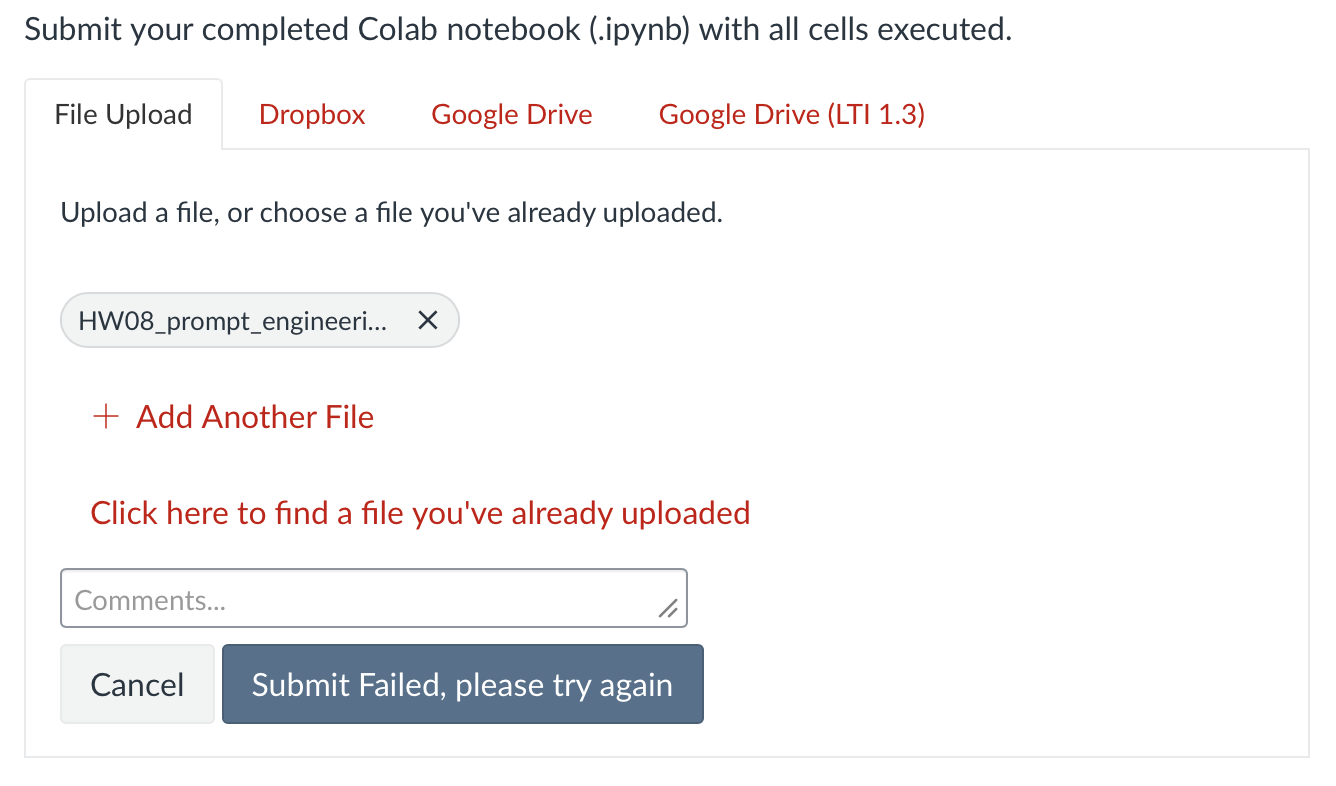

## 🤔 Debrief

1. Your v4 prompt works today, on this model. What happens when the model is upgraded
   next quarter — how does a team catch a prompt that silently got worse? (Hint: your
   `score_prompt` test set is the seed of the answer, and of **Q4**.)
2. Few-shot examples cost tokens on every single call. At 1M calls/month, when is a
   longer prompt the wrong business decision — and what are the alternatives?


## 📤 Submit (HW8 — 40 points)

**Deliverables (submit through Canvas):**
- Completed `.ipynb` executed top-to-bottom, INCLUDING the 🎮 Playground with your own domain's template class and a v1→v2 iteration
- Your v1→v4 iteration table and the final results-summary table (markdown cells)
- Your insider-test writeup on the Playground outputs

**Answer these questions in a markdown cell at the end of your notebook:**
- **Q1:** Which prompting technique worked best for your task? Why?
- **Q2:** Show your prompt iteration history. What improved results most?
- **Q3:** When did few-shot outperform zero-shot? When didn't it matter?
- **Q4:** How would you A/B test prompts in a production system?

**Grading:**

| Part | Points |
|---|---|
| Part 1: Setup and Zero-Shot Prompts | 6 |
| Part 2: Few-Shot Prompts | 10 |
| Part 3: Chain-of-Thought Prompting | 10 |
| Part 4: Prompt Optimization | 8 |
| Part 5: Documentation | 6 |

**Due Sunday 10:00 p.m.** — see the Canvas assignment for the exact date. Late work is not accepted (see syllabus).

*AI policy: AI tools are allowed and encouraged. Add one line acknowledging what you used, and be ready to explain every part of what you submit.*
